# Assignment 2: Logistic Regression

**Completed analysis with detailed explanations**  
Source: supplied Columbia Speed Dating CSV and `Speed Dating Data Key.doc`. The original questions are preserved below; answers appear in Markdown cells and computed results remain visible.

**Main findings.** Associations with sending a like differ by gender in this sample. For receiving a like, the pooled model finds a negative conditional association for the intelligence gap, but no statistically significant association for the other three gaps at 5%. A gender-interaction extension suggests that pooling can obscure differences. These are observational, post-date associations, not causal effects or validated forecasts.

**Reading and rerunning.** Keep this notebook beside `SpeedDatingData.csv`. Run all cells in order. Required packages: numpy, pandas, matplotlib, scipy, statsmodels, scikit-learn, patsy and Jupyter. We use statsmodels' formula interface (Patsy) in place of the starter's ISLP `ModelSpec`; it fits the same binomial-logit model and makes the interactions explicit. No ISLP installation is needed. Gender is coded 0 = female and 1 = male in the supplied key.

**Unit of analysis and inference.** A row is one participant's perspective on one date, not an independent person. The same participant appears repeatedly, and reciprocal records describe the same encounter. Main assignment tables use conventional GLM standard errors, as in the starter. A participant-clustered sensitivity analysis at the end shows how repeated observations affect uncertainty. Even that check does not fully resolve dependence through partners, reciprocal dates and event waves. All significance statements are conditional on these limitations.

**Overview:**

In this assignment, you will conduct two additional analyses of the Columbia Speed Dating Experiment using logistic regression.
1. Test whether the associations between profile features (e.g., demographic variables and trait ratings) and sending a like differ by gender.
2. Test whether an overconfidence proxy is associated with receiving a like.

**Instructions:**

1. Put all written answers in the markdown cells below the question statement.
2. Keep code output.
3. Each group submits 1 notebook. 
 

## Set up dataset

Cell output is not required
<h4 style="color:blue">Complete the code cells below:</h4> 

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import chi2
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices
from IPython.display import display
from sklearn.metrics import confusion_matrix, accuracy_score, RocCurveDisplay, roc_auc_score

pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
def coefficient_table(model):
    ci = model.conf_int()
    return pd.DataFrame({'Coefficient': model.params, 'StdError': model.bse,
                         'p_value': model.pvalues, 'OddsRatio': np.exp(model.params),
                         'OR_CI_low': np.exp(ci[0]), 'OR_CI_high': np.exp(ci[1])})
print('Python:', platform.python_version(), '| pandas:', pd.__version__,
      '| statsmodels:', statsmodels.__version__, '| scipy:', scipy.__version__)

Python: 3.12.14 | pandas: 3.0.6 | statsmodels: 0.15.0 | scipy: 1.18.1


In [2]:
# Portable input: run from this notebook's folder.
data_path = Path('SpeedDatingData.csv')
if not data_path.exists():
    raise FileNotFoundError('Place SpeedDatingData.csv beside this notebook and run from that folder.')
dating_raw = pd.read_csv(data_path, encoding='ISO-8859-1')
dating = dating_raw.loc[~dating_raw['wave'].isin([6, 7, 8, 9])].copy()
print(f'Raw rows: {len(dating_raw):,}; excluded waves 6–9: {len(dating_raw)-len(dating):,}; retained: {len(dating):,}')

Raw rows: 8,378; excluded waves 6–9: 1,562; retained: 6,816


In [3]:
#====== Extract Relavant Vars:
pre_cols = [
    "iid", "gender", "age",  
    # self-eval (pre-survey)
    "attr3_1", "intel3_1", "sinc3_1", "fun3_1", 
     # partner-eval (date)
    "attr_o", "sinc_o", "intel_o","fun_o", 
    #eval of partner
    "attr","sinc","intel","fun",
    # match data (dating outcome)
      "dec","dec_o" ]

dating_sample=dating[pre_cols]

### Task 0: General Information of the Data

1. Report the total # of rows with missing values (cell output)
2. For each variable, compute the  total # of missing values and the percentage of missing values in the same table (cell output)

<h4 style="color:blue">Please complete the code cells below:</h4> 

In [4]:
missing_total = dating_sample.isna().any(axis=1).sum()
total_record = len(dating_sample)
print(f'Out of {total_record:,} records, {missing_total:,} have at least one missing value '
      f'({missing_total / total_record:.2%}).')

Out of 6,816 records, 751 have at least one missing value (11.02%).


In [5]:
missing_counts = dating_sample.isna().sum()
missing_ratio = 100 * missing_counts / total_record
missing_summary = pd.DataFrame({'MissingCount': missing_counts, 'MissingRatio': missing_ratio})
missing_summary = missing_summary.sort_values('MissingRatio', ascending=False)
print('MissingRatio is the percentage of all retained records. All variables are shown.')
display(missing_summary)

MissingRatio is the percentage of all retained records. All variables are shown.


,MissingCount,MissingRatio
fun_o,305,4.4748
fun,295,4.3281
intel_o,276,4.0493
intel,266,3.9026
sinc_o,263,3.8586
sinc,253,3.7119
attr_o,204,2.9930
attr,194,2.8462
attr3_1,100,1.4671
intel3_1,100,1.4671


In [6]:
# Drop incomplete ROWS, not columns, to preserve the requested variables.
dating_sample_0 = dating_sample.dropna().copy()
assert dating_sample_0['gender'].isin([0, 1]).all()
assert dating_sample_0[['dec', 'dec_o']].isin([0, 1]).all().all()
print(f'Complete-case rows: {len(dating_sample_0):,}; unique participants: {dating_sample_0.iid.nunique():,}')
display(dating_sample_0.groupby('gender').agg(Rows=('iid','size'), Participants=('iid','nunique'),
    SendLikeRate=('dec','mean'), ReceiveLikeRate=('dec_o','mean')))
print('Complete-case proportion by gender:')
display(dating_sample_0.groupby('gender').size() / dating_sample.groupby('gender').size())

Complete-case rows: 6,065; unique participants: 437


,Rows,Participants,SendLikeRate,ReceiveLikeRate
gender,,,,
0,3018,216,0.3983,0.4649
1,3047,221,0.4654,0.3945


Complete-case proportion by gender:


gender
0    0.8869
1    0.8928
dtype: float64

##  Task 1: 

### We are curious about: 
Whether the correlations between profile features (e.g., demographic vars, traits rating) and 'sending a like' differs by gender.

#### Question 1.1: Write down the regression model you would try first.

 

  <h4 style="color:blue">(Write your answer here)</h4>


 

Let $p_{ij}=P(dec_{ij}=1\mid X_{ij})$ be the probability that participant $i$ sends a like to partner $j$. Start with

$$\log\left(\frac{p_{ij}}{1-p_{ij}}\right)=\beta_0+\beta_G G_i+\sum_{k=1}^{9}\beta_k X_{k,ij}+\sum_{k=1}^{9}\gamma_k(G_iX_{k,ij}).$$

Here $G_i$ is gender, and $X$ contains `age`, four self-ratings (`attr3_1`, `intel3_1`, `sinc3_1`, `fun3_1`), and four ratings the participant gives their partner (`attr`, `intel`, `sinc`, `fun`). These predictors describe the decision maker and how they perceive the person they might like. Each gender interaction directly tests whether a slope differs between genders. Simply fitting gender as an additive predictor would allow different intercepts but would not answer whether trait associations differ.

For females, the slope of predictor $k$ is $\beta_k$; for males, it is $\beta_k+\gamma_k$. Thus $e^{\gamma_k}$ is the ratio of the male odds ratio to the female odds ratio. The gender main coefficient alone compares genders when every numerical predictor equals zero, an unrealistic reference here, so it is not an overall gender difference.

The model excludes `iid` because it is an identifier; it excludes `dec_o` because the partner's concurrent decision is another outcome. It also omits the partner's ratings of the participant (`*_o`) from this first specification to focus on the sender's perceptions. This is a justified starting specification, not the only possible model. Assume a linear log-odds relationship for numerical scores, additive effects except for the stated interactions, and no perfect separation. Ratings are treated as approximately numerical even though they are ordered scales.

**Preparation and missingness.** The supplied instructions exclude waves 6–9; the key also documents a different preference-question scale for those waves. This does not imply every selected variable changed scale. After exclusion, 6,816 directed records remain; 751 (11.02%) have missing data in the selected variables, leaving 6,065 rows from 437 participants. We follow the requested complete-case approach on all selected columns so model comparisons use identical observations. This also removes some rows for variables not used by a particular model. Missingness may be systematic, so these estimates describe retained records and may not generalize to all participants. Repeated rows per person are not extra independent participants.

---

#### Question 1.2: In this model, which variables are numerical / nominal 

<h4 style="color:blue">(Write your answer here)</h4>

| Role | Variables | Treatment |
|---|---|---|
| Binary response | `dec` | 1 = sends a like; 0 = does not |
| Nominal predictor | `gender` | Binary indicator, female = reference (0), male = 1; numerical storage does not make gender a continuous quantity |
| Numerical predictor | `age` | Years; coefficient is per additional year |
| Ordered scores treated as numerical | `attr3_1`, `intel3_1`, `sinc3_1`, `fun3_1`, `attr`, `intel`, `sinc`, `fun` | A one-unit change means one rating point; assumes equal spacing and a linear log-odds relationship |
| Interaction terms | Gender × each numerical predictor | Products that allow gender-specific slopes; not separate raw measurements |
| Identifier | `iid` | Labels participants; excluded as a numerical predictor |

The fitted intercept is a model parameter, not a measured variable. In Task 2, `dec_o` is another binary response; partner ratings and gaps are numerical predictors. A positive gap means self-rating exceeds partner rating, and a negative gap means the reverse.

---
#### Question 1.3: Please complete the regression

1. Report the **`significant` regression coefficient(s)**, and their **p-value** in the cell output 
2. Report the  **`insignificant` regression coefficient(s)** in the cell output (use threshold 0.1)
 
<h4 style="color:blue">(Complete the code cells)</h4>


In [7]:
profile_terms = ['age', 'attr3_1', 'intel3_1', 'sinc3_1', 'fun3_1',
                 'attr', 'sinc', 'intel', 'fun']
full_formula = 'dec ~ gender * (' + ' + '.join(profile_terms) + ')'
y_int, X_int = dmatrices(full_formula, dating_sample_0, return_type='dataframe')
glm_full = sm.GLM(y_int.iloc[:, 0], X_int, family=sm.families.Binomial()).fit()
glm_full_summary = coefficient_table(glm_full)
glm_int_summary_sig = glm_full_summary.loc[glm_full_summary.p_value < 0.10]
glm_int_summary_insig = glm_full_summary.loc[glm_full_summary.p_value >= 0.10]
print('Original model:', full_formula)
print('Significant at 10% (including intercept if applicable):')
display(glm_int_summary_sig)
print('Not significant at 10%:')
display(glm_int_summary_insig)

Original model: dec ~ gender * (age + attr3_1 + intel3_1 + sinc3_1 + fun3_1 + attr + sinc + intel + fun)
Significant at 10% (including intercept if applicable):


,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high
Intercept,-4.5659,0.5539,1.6770e-16,0.0104,0.0035,0.0308
attr3_1,-0.2053,0.0362,1.4105e-08,0.8144,0.7586,0.8743
intel3_1,0.0860,0.0451,5.6420e-02,1.0898,0.9977,1.1904
sinc3_1,-0.1704,0.0333,3.0667e-07,0.8434,0.7901,0.9002
attr,0.4431,0.0305,9.7927e-48,1.5575,1.4670,1.6535
intel,0.0934,0.0425,2.7962e-02,1.0979,1.0102,1.1932
fun,0.3470,0.0315,2.8787e-28,1.4148,1.3302,1.5048
gender:age,-0.0719,0.0181,7.1617e-05,0.9306,0.8981,0.9642
gender:attr3_1,0.1879,0.0517,2.7638e-04,1.2067,1.0905,1.3354
gender:intel3_1,0.1715,0.0641,7.4860e-03,1.1871,1.0469,1.3461


Not significant at 10%:


,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high
gender,0.2368,0.8098,0.7699,1.2672,0.2592,6.1963
age,0.0186,0.0118,0.1143,1.0188,0.9955,1.0427
fun3_1,0.0499,0.0344,0.1478,1.0511,0.9825,1.1245
sinc,-0.0333,0.0349,0.3405,0.9673,0.9033,1.0358
gender:sinc3_1,0.0710,0.0467,0.1284,1.0735,0.9797,1.1764
gender:sinc,-0.0800,0.0521,0.1244,0.9231,0.8335,1.0223
gender:fun,0.0256,0.0467,0.5843,1.0259,0.9361,1.1243


---
#### Question 1.4: Please complete the code below 

 Based on the regression results, propose and estimate an appropriate reduced model. Clearly identify which terms you retained or removed and justify each decision. Compare the reduced model with the original model and explain whether your substantive conclusions change.

 
<h4 style="color:blue">(Complete the code cells below)</h4>


In [8]:
# Reduce only gender interactions; preserve all main effects for hierarchy and adjustment.
interaction_terms = [name for name in glm_full.params.index if ':' in name]
retained_interactions = [name for name in interaction_terms if glm_full.pvalues[name] < .10]
removed_interactions = [name for name in interaction_terms if name not in retained_interactions]
reduced_formula = 'dec ~ gender + ' + ' + '.join(profile_terms + retained_interactions)
y_int, X_int = dmatrices(reduced_formula, dating_sample_0, return_type='dataframe')
y_int = y_int.iloc[:, 0]
glm_int = sm.GLM(y_int, X_int, family=sm.families.Binomial()).fit()
glm_int_summary = coefficient_table(glm_int)
print('Retained interactions:', retained_interactions)
print('Removed interactions:', removed_interactions)
print('Reduced model:', reduced_formula)
print('Reduced-model terms significant at 10%:')
display(glm_int_summary.loc[glm_int_summary.p_value < .10])
print('All reduced-model terms, including retained nonsignificant adjustments:')
display(glm_int_summary)
reduction_lr = 2 * (glm_full.llf - glm_int.llf)
reduction_df = int(glm_full.df_model - glm_int.df_model)
print(f'Nested LR comparison: statistic={reduction_lr:.4f}, df={reduction_df}, '
      f'p={chi2.sf(reduction_lr, reduction_df):.6f}')
display(pd.DataFrame({'Model':['Original','Reduced'], 'Parameters':[len(glm_full.params),len(glm_int.params)],
                     'AIC':[glm_full.aic,glm_int.aic], 'LogLikelihood':[glm_full.llf,glm_int.llf]}))
# Overall test of all nine gender differences in the original model.
restriction = np.zeros((len(interaction_terms), len(glm_full.params)))
for i, term in enumerate(interaction_terms):
    restriction[i, glm_full.params.index.get_loc(term)] = 1
print('Joint Wald test: all original gender interactions = 0')
print(glm_full.wald_test(restriction, scalar=True))
# Obtain the correct male slope by adding main and interaction terms.
slope_rows = []
for term in profile_terms:
    for gender_value, gender_label in [(0,'Female'), (1,'Male')]:
        contrast = np.zeros(len(glm_int.params))
        contrast[glm_int.params.index.get_loc(term)] = 1
        interaction = 'gender:' + term
        if gender_value and interaction in glm_int.params.index:
            contrast[glm_int.params.index.get_loc(interaction)] = 1
        test = glm_int.t_test(contrast)
        b = float(np.asarray(test.effect).item())
        slope_rows.append([term, gender_label, b, np.exp(b), float(np.asarray(test.pvalue).item())])
gender_slopes = pd.DataFrame(slope_rows, columns=['Predictor','Gender','Slope','OddsRatio','p_value'])
display(gender_slopes)

Retained interactions: ['gender:age', 'gender:attr3_1', 'gender:intel3_1', 'gender:fun3_1', 'gender:attr', 'gender:intel']
Removed interactions: ['gender:sinc3_1', 'gender:sinc', 'gender:fun']
Reduced model: dec ~ gender + age + attr3_1 + intel3_1 + sinc3_1 + fun3_1 + attr + sinc + intel + fun + gender:age + gender:attr3_1 + gender:intel3_1 + gender:fun3_1 + gender:attr + gender:intel
Reduced-model terms significant at 10%:


,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high
Intercept,-4.6658,0.5464,1.3441e-17,0.0094,0.0032,0.0275
attr3_1,-0.2073,0.0361,9.4412e-09,0.8128,0.7572,0.8724
intel3_1,0.0765,0.0447,8.6689e-02,1.0795,0.9890,1.1783
sinc3_1,-0.1350,0.0234,7.4417e-09,0.8737,0.8346,0.9146
attr,0.4433,0.0299,7.8217e-50,1.5579,1.4693,1.6518
sinc,-0.0689,0.0258,7.6636e-03,0.9334,0.8873,0.9819
intel,0.1107,0.0388,4.3605e-03,1.1171,1.0352,1.2054
fun,0.3572,0.0232,2.1796e-53,1.4294,1.3658,1.4960
gender:age,-0.0731,0.0181,5.2129e-05,0.9295,0.8972,0.9630
gender:attr3_1,0.1897,0.0517,2.4101e-04,1.2089,1.0925,1.3377


All reduced-model terms, including retained nonsignificant adjustments:


,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high
Intercept,-4.6658,0.5464,1.3441e-17,0.0094,0.0032,0.0275
gender,0.5326,0.7731,4.9092e-01,1.7033,0.3743,7.7516
age,0.0172,0.0118,1.4245e-01,1.0174,0.9942,1.0411
attr3_1,-0.2073,0.0361,9.4412e-09,0.8128,0.7572,0.8724
intel3_1,0.0765,0.0447,8.6689e-02,1.0795,0.9890,1.1783
sinc3_1,-0.1350,0.0234,7.4417e-09,0.8737,0.8346,0.9146
fun3_1,0.0483,0.0344,1.6005e-01,1.0495,0.9811,1.1226
attr,0.4433,0.0299,7.8217e-50,1.5579,1.4693,1.6518
sinc,-0.0689,0.0258,7.6636e-03,0.9334,0.8873,0.9819
intel,0.1107,0.0388,4.3605e-03,1.1171,1.0352,1.2054


Nested LR comparison: statistic=4.5198, df=3, p=0.210528


,Model,Parameters,AIC,LogLikelihood
0,Original,20,6322.7409,-3141.3705
1,Reduced,17,6321.2608,-3143.6304


Joint Wald test: all original gender interactions = 0
<Wald test (chi2): statistic=79.286997894867, p-value=2.238973894070479e-13, df_denom=9>


,Predictor,Gender,Slope,OddsRatio,p_value
0,age,Female,0.0172,1.0174,1.4245e-01
1,age,Male,-0.0558,0.9457,4.2321e-05
2,attr3_1,Female,-0.2073,0.8128,9.4412e-09
3,attr3_1,Male,-0.0176,0.9825,6.3221e-01
4,intel3_1,Female,0.0765,1.0795,8.6689e-02
5,intel3_1,Male,0.2648,1.3031,3.8921e-09
6,sinc3_1,Female,-0.1350,0.8737,7.4417e-09
7,sinc3_1,Male,-0.1350,0.8737,7.4417e-09
8,fun3_1,Female,0.0483,1.0495,1.6005e-01
9,fun3_1,Male,-0.0967,0.9079,1.0639e-03


<h4 style="color:blue">(Write your explanations)</h4>

**Reduction rule.** At the specified 10% threshold, remove `gender:sinc3_1` (p = 0.1284), `gender:sinc` (p = 0.1244), and `gender:fun` (p = 0.5843). These interaction estimates do not provide sufficient evidence that the corresponding slopes differ by gender. Keep the other six interactions because their original-model p-values are below 0.10.

Retain **all nine numerical main effects and gender**. For `age`, `attr3_1`, `intel3_1`, `fun3_1`, `attr`, and `intel`, both main effects belonging to each retained interaction are required by the hierarchy principle, even if a main-effect p-value is large. Keep `sinc3_1`, `sinc`, and `fun` as common slopes because their main effects adjust for related characteristics; in the reduced model all three are significant. Removing an interaction constrains two slopes to equality; it does not justify deleting that variable entirely.

The original model has 20 parameters and the reduced model has 17. Their log likelihoods are −3141.370 and −3143.630, respectively. A nested likelihood-ratio comparison gives χ²(3) = 4.520, p = 0.2105: we do not detect a substantial loss of fit from those three restrictions. AIC decreases slightly from 6322.741 to 6321.261 (lower is preferred). A difference of only 1.480 is modest, so parsimony is the main reason to use the reduced model. Both comparisons use exactly the same 6,065 rows and outcome.

The major positive associations for perceived attractiveness and fun remain, and the retained gender differences remain. However, the sincerity-rating main effect changes from a female-specific, nonsignificant estimate in the full model to a significant common slope after the gender difference is constrained to zero. Thus the broad conclusion is stable, but every individual term does not have identical significance.

**Caution.** Selection and testing use the same data. The nested comparison and subsequent p-values are exploratory and do not account for model selection. Nonsignificance is not proof of identical slopes. Repeated-date dependence also limits the conventional p-values.

### Question 1.5 — Observation & Interpretation

**a) Model refinement.**  
If you remove insignificant predictors (if any), briefly describe what has changed (coefficients, fit, key conclusions). 



**b) Interpret significant coefficients.**  

Hint:
- **Sign** (direction of effect)  
- **Magnitude** 
- **Plain-English meaning** 



**c) Hypothesis test (choose one significant coefficient).**  
State the hypotheses and interpret the p-value.

Hint:
- Variable: `_____`  
- **Null (H₀):** 
- **Alternative (H₁):** 
- p-value: `_____`  
- Interpretation of p-value (in text):  



**d) Do effects differ by gender?**  
Hint: Use your regression model to respond:

> **Do the correlations between profile features and 'sending a like' differ by gender?**

 
<h4 style="color:blue">(Write your answer here)</h4>

**a) Model refinement.** Removing three weak interactions changes some coefficient estimates because the model now estimates common sincerity and fun slopes using both genders. The slight AIC improvement and nonsignificant LR test support a smaller descriptive model, with the selection caveats noted above. This does not establish that it will predict better for new people.

**b) Significant coefficients: direction, magnitude and meaning.** All interpretations hold the other included predictors fixed. Logistic coefficients are changes in **log odds**, not changes in probability. An odds ratio (OR) of 1.56 means 56% higher odds, not 56 percentage points higher probability. For a starting probability $p$, multiplying odds by OR gives $p'=OR\,p/(1-p+OR\,p)$; the probability change therefore depends on $p$.

The table below shows the slopes implied by the reduced model. It includes nonsignificant slopes for context; the code above tests each combined gender-specific slope using its full covariance, rather than assuming that significance of an interaction establishes significance of each group's slope.

| Predictor | Female slope | Female OR | Male slope | Male OR |
|---|---:|---:|---:|---:|
| `age` | 0.0172 | 1.017 | -0.0558 | 0.946 |
| `attr3_1` | -0.2073 | 0.813 | -0.0176 | 0.983 |
| `intel3_1` | 0.0765 | 1.080 | 0.2648 | 1.303 |
| `sinc3_1` | -0.1350 | 0.874 | -0.1350 | 0.874 |
| `fun3_1` | 0.0483 | 1.049 | -0.0967 | 0.908 |
| `attr` | 0.4433 | 1.558 | 0.6477 | 1.911 |
| `sinc` | -0.0689 | 0.933 | -0.0689 | 0.933 |
| `intel` | 0.1107 | 1.117 | -0.1247 | 0.883 |
| `fun` | 0.3572 | 1.429 | 0.3572 | 1.429 |

- **Self-rated attractiveness (`attr3_1`).** The female coefficient is −0.2073 (p = 9.44×10⁻⁹), OR = 0.813: a one-point higher self-rating is associated with about 18.7% lower odds of sending a like. The male interaction is +0.1897 (p = 0.000241), so the male slope is only −0.0176. The interaction says the two slopes differ; it does not imply a positive male slope. One possible explanation is differences in selectivity, but this regression does not test that mechanism.
- **Self-rated intelligence (`intel3_1`).** The female coefficient is +0.0765 (p = 0.0867), OR = 1.080, significant at the assignment's 10% level but not at 5%. The male interaction is +0.1883 (p = 0.00270), producing a male slope of +0.2648 and OR = 1.303. This is a conditional association with sending a like, not evidence that intelligence causes greater interest.
- **Self-rated sincerity (`sinc3_1`).** The common slope is −0.1350 (p = 7.44×10⁻⁹), OR = 0.874: about 12.6% lower odds per one-point higher self-rating. Equality between genders is an imposed restriction after reduction.
- **Partner attractiveness rated by the sender (`attr`).** The female slope is +0.4433 (p = 7.82×10⁻⁵⁰), OR = 1.558. The male interaction is +0.2044 (p = 3.37×10⁻⁶), making the male slope +0.6477 and OR = 1.911. Thus a one-point higher attractiveness rating is associated with 55.8% higher female odds and 91.1% higher male odds of sending a like.
- **Partner sincerity rated by the sender (`sinc`).** The common coefficient is −0.0689 (p = 0.00766), OR = 0.933, or about 6.7% lower odds per point. This is a partial association after controlling for correlated ratings. It does not mean sincerity is generally undesirable; correlated ratings and omitted traits can change conditional signs.
- **Partner intelligence rated by the sender (`intel`).** The female coefficient is +0.1107 (p = 0.00436), OR = 1.117. The male interaction is −0.2355 (p = 9.14×10⁻⁷), producing a male slope of −0.1247 and OR = 0.883. The partial association changes direction across genders in this fitted model.
- **Partner fun rated by the sender (`fun`).** The common coefficient is +0.3572 (p = 2.18×10⁻⁵³), OR = 1.429: about 42.9% higher odds per rating point, conditional on the other variables.
- **Age interaction.** `gender:age` = −0.0731 (p = 0.0000521). The female age slope is +0.0172 and is not significant by itself (p = 0.142). The male slope is −0.0558, OR = 0.946 per year. The significant interaction indicates a more negative age association for males.
- **Self-rated fun interaction.** `gender:fun3_1` = −0.1450 (p = 0.00132). The female main slope is +0.0483 and is not significant (p = 0.160). The male slope is −0.0967, OR = 0.908. Again, the significant term is the difference in slopes.

The intercept (−4.6658) is also statistically significant, but describes a hypothetical female with age and every score equal to zero, outside the observed setting. It is needed to position the logistic curve and has little substantive value here. The nonsignificant gender main term should not be read as evidence of no gender differences because the model includes gender interactions.

**c) Hypothesis test.** Choose `gender:attr` in the reduced model. H₀: $\gamma_{attr}=0$ (the attractiveness-rating slope is equal across genders); H₁: $\gamma_{attr}\ne0$. The estimate is +0.2044 and the two-sided Wald p-value is approximately 0.00000337. If the null and model assumptions were true, a Wald statistic at least as extreme in absolute value would be very unlikely. Reject H₀ at 10% and 5%; the estimated attractiveness association is stronger for males. The p-value is not the probability that H₀ is true, and the conclusion remains exploratory because of selection and dependence.

**d) Do associations differ by gender?** Yes, under the conventional model-based analysis. Six retained interactions indicate differences for age, self-rated attractiveness, self-rated intelligence, self-rated fun, perceived partner attractiveness and perceived partner intelligence. The joint original-model test gives Wald χ²(9) = 79.287, p = 2.24×10⁻¹³; it tests all nine interactions, so the overall question is assessed directly rather than relying only on selected terms. There is insufficient evidence at 10% to retain gender differences for self-rated sincerity, perceived partner sincerity or perceived partner fun. These are sample-specific conditional associations; they do not establish universal gender preferences or causal differences.

### Question 1.6 — Prediction Accuracy

Please use the last model to predict the outcomes (sending like) and in the cell output, please report  

1. accuracy rate
2. confusion table
3. ROC curve
4. AUC

<h4 style="color:blue">(Complete the code cells below)</h4>

In [9]:
# Requested predictions use the last (reduced) fitted model on its estimation data.
probs = glm_int.predict(X_int)
assert np.isfinite(probs).all() and probs.between(0, 1).all()

In [10]:
threshold = 0.5
labels = np.where(probs >= threshold, 1, 0)

In [11]:
# Rows are actual outcomes; columns are predicted outcomes.
cm_array = confusion_matrix(y_int, labels, labels=[0, 1])
cm = pd.DataFrame(cm_array, index=['Actual no (0)', 'Actual yes (1)'],
                  columns=['Predicted no (0)', 'Predicted yes (1)'])
display(cm)

,Predicted no (0),Predicted yes (1)
Actual no (0),2741,704
Actual yes (1),851,1769


In [12]:
tn, fp, fn, tp = cm_array.ravel()  # sklearn ordering: TN, FP, FN, TP
accuracy = (tn + tp) / cm_array.sum()
assert np.isclose(accuracy, accuracy_score(y_int, labels))
print(f'Accuracy: {accuracy:.3f} ({accuracy:.2%})')
print(f'Majority-class baseline: {max(y_int.mean(), 1-y_int.mean()):.3f}')
print(f'Sensitivity: {tp/(tp+fn):.3f}; specificity: {tn/(tn+fp):.3f}')
print('These are apparent/in-sample metrics, not held-out predictive accuracy.')

Accuracy: 0.744 (74.36%)
Majority-class baseline: 0.568
Sensitivity: 0.675; specificity: 0.796
These are apparent/in-sample metrics, not held-out predictive accuracy.


AUC: 0.818


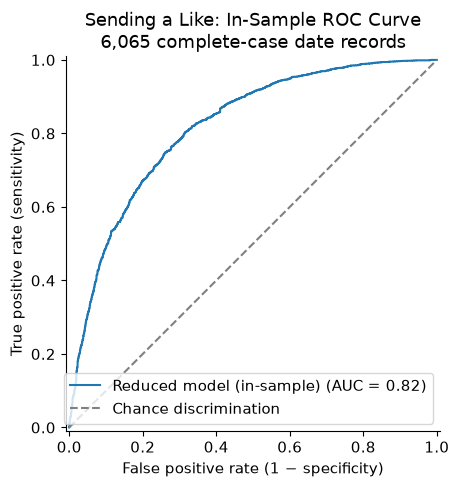

In [13]:
auc = roc_auc_score(y_int, probs)
print(f'AUC: {auc:.3f}')
RocCurveDisplay.from_predictions(y_int, probs, name='Reduced model (in-sample)')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Chance discrimination')
plt.title('Sending a Like: In-Sample ROC Curve\n6,065 complete-case date records')
plt.xlabel('False positive rate (1 − specificity)')
plt.ylabel('True positive rate (sensitivity)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('task1_roc.png', dpi=160, bbox_inches='tight')
plt.show()

**How to read the prediction output.** Accuracy is the fraction classified correctly at the specified 0.5 cutoff. The confusion table uses actual outcomes as rows and predictions as columns, so false negatives are actual likes predicted as no and false positives are actual no decisions predicted as likes. The ROC curve varies the cutoff: sensitivity increases as the threshold is lowered, typically at the cost of more false positives. AUC summarizes discrimination across cutoffs and equals the probability that a randomly selected positive record receives a higher predicted score than a randomly selected negative record (with half credit for ties). It does not measure calibration or establish causal validity.

These predictions reuse the model-fitting data and the same data that informed model reduction. Consequently the displayed accuracy and AUC are **in-sample**, and usually optimistic for future participants. The majority-class baseline provides context for accuracy. A reliable generalization estimate would require holding out participants and performing model selection within training data; because dates connect participants, preventing both members of a test encounter from entering training would require a carefully designed split. No such estimate is claimed here.

**Observed performance:** accuracy = 74.36%, compared with a 56.80% majority-class baseline; AUC = 0.818. Sensitivity is 0.675 and specificity is 0.796. These values describe these 6,065 fitting records only.

## Task 2: 

### We are curious about:

Whether an **overconfidence proxy** is associated with **receiving a like**.

For each selected trait (e.g., sincerity), we define the overconfidence proxy as:

`<trait>_gap = self-rating of the trait − partner’s rating of the trait`

A positive gap indicates that the participant rated themselves more highly than their partner did. We will examine whether these trait-gap variables, together with other relevant factors such as gender and the partner’s ratings, are associated with whether the participant **receives a like from their partner**.

**Be careful:** This outcome is not whether the participant sends a like.

### Question 2.1: 

Please follow the hint in the code cell below to create the  `< trait >_gap` variable for each trait and create a new dataset `dating_sample_gap`for analysis.  Report the first 10-15 rows of this dataset in the cell output

*HINT:* Please read the variable decription (word doc in assignment folder) carefully to make sure you select the correct variables.  
 
<h4 style="color:blue">(Complete the code cells)</h4>

In [14]:
dating_sample_gap = dating_sample_0.copy()
self_var = ['attr3_1', 'intel3_1', 'sinc3_1', 'fun3_1']
other_val = ['attr_o', 'intel_o', 'sinc_o', 'fun_o']
bases = ['attr', 'intel', 'sinc', 'fun']
for b, s, o in zip(bases, self_var, other_val):
    dating_sample_gap[b + '_gap'] = dating_sample_gap[s] - dating_sample_gap[o]
gap_cols = [b + '_gap' for b in bases]
print('Positive gap = self-rating exceeds the partner rating of this participant.')
display(dating_sample_gap.head(12))

Positive gap = self-rating exceeds the partner rating of this participant.


,iid,gender,age,attr3_1,intel3_1,sinc3_1,fun3_1,attr_o,sinc_o,intel_o,fun_o,attr,sinc,intel,fun,dec,dec_o,attr_gap,intel_gap,sinc_gap,fun_gap
0,1,0,21.0,6.0,8.0,8.0,8.0,6.0,8.0,8.0,8.0,6.0,9.0,7.0,7.0,1,0,0.0,0.0,0.0,0.0
1,1,0,21.0,6.0,8.0,8.0,8.0,7.0,8.0,10.0,7.0,7.0,8.0,7.0,8.0,1,0,-1.0,-2.0,0.0,1.0
2,1,0,21.0,6.0,8.0,8.0,8.0,10.0,10.0,10.0,10.0,5.0,8.0,9.0,8.0,1,1,-4.0,-2.0,-2.0,-2.0
3,1,0,21.0,6.0,8.0,8.0,8.0,7.0,8.0,9.0,8.0,7.0,6.0,8.0,7.0,1,1,-1.0,-1.0,0.0,0.0
4,1,0,21.0,6.0,8.0,8.0,8.0,8.0,7.0,9.0,6.0,5.0,6.0,7.0,7.0,1,1,-2.0,-1.0,1.0,2.0
5,1,0,21.0,6.0,8.0,8.0,8.0,7.0,7.0,8.0,8.0,4.0,9.0,7.0,4.0,0,1,-1.0,0.0,1.0,0.0
6,1,0,21.0,6.0,8.0,8.0,8.0,3.0,6.0,7.0,5.0,7.0,6.0,7.0,4.0,1,0,3.0,1.0,2.0,3.0
7,1,0,21.0,6.0,8.0,8.0,8.0,6.0,7.0,5.0,6.0,4.0,9.0,7.0,6.0,0,0,0.0,3.0,1.0,2.0
8,1,0,21.0,6.0,8.0,8.0,8.0,7.0,7.0,8.0,8.0,7.0,6.0,8.0,9.0,1,1,-1.0,0.0,1.0,0.0
9,1,0,21.0,6.0,8.0,8.0,8.0,6.0,6.0,6.0,6.0,5.0,6.0,6.0,8.0,1,0,0.0,2.0,2.0,2.0


### Question 2.2: 

Please draw the bar chart to compare the mean of '_gap' between genders. Report the graph in the cell output. 
 
<h4 style="color:blue">(Complete the code cells)</h4>

gender,Female,Male
attr_gap,0.6801,1.0345
intel_gap,0.9254,1.0870
sinc_gap,1.1579,1.0911
fun_gap,1.2917,1.3129


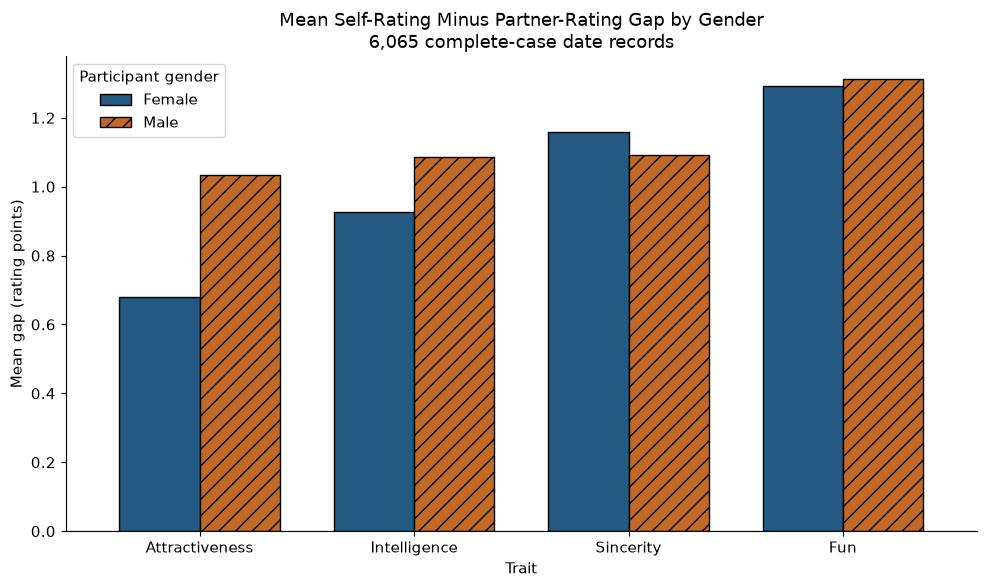

Descriptive date-weighted means; no hypothesis test or confidence interval is implied.


In [15]:
gap = dating_sample_gap.groupby('gender')[gap_cols].mean().T
gap = gap.rename(columns={0: 'Female', 1: 'Male'})
display(gap)
ax = gap.plot(kind='bar', figsize=(10, 6), color=['#245A81', '#C16A28'],
              edgecolor='black', width=0.75)
# Hatch is an additional cue beyond color.
for patch in ax.containers[1]:
    patch.set_hatch('//')
ax.axhline(0, color='black', linewidth=.8)
ax.set_title('Mean Self-Rating Minus Partner-Rating Gap by Gender\n6,065 complete-case date records')
ax.set_ylabel('Mean gap (rating points)')
ax.set_xlabel('Trait')
ax.set_xticklabels(['Attractiveness', 'Intelligence', 'Sincerity', 'Fun'], rotation=0)
ax.legend(title='Participant gender')
plt.tight_layout()
plt.savefig('task2_mean_gaps.png', dpi=160, bbox_inches='tight')
plt.show()
print('Descriptive date-weighted means; no hypothesis test or confidence interval is implied.')

### Question 2.3

We will examine which factors are associated with whether a participant **receives a like from their partner**. What is the dependent variable in this regression? Write the variable name and briefly explain why it represents receiving, rather than sending, a like.

<h4 style="color:blue">(Write your answer here)</h4>

The dependent variable is **`dec_o`**, the partner's decision about whether they would like to see the focal participant again (1 = yes; 0 = no). A yes means the focal participant **receives** a like. By contrast, `dec` is the focal participant's own decision and represents **sending** a like. Neither variable by itself is a mutual match; a match requires both decisions to be yes.

The same direction matters for ratings: `attr_o`, `intel_o`, `sinc_o` and `fun_o` are ratings the partner gives the focal participant. Unsuffixed `attr`, `intel`, `sinc` and `fun` describe the focal participant's ratings of the partner. Therefore, for example, `intel_gap = intel3_1 − intel_o`. The key sometimes abbreviates intelligence as `int3_1`; the supplied CSV and starter use `intel3_1`, which is the column used here.

All four mean gaps are positive for both genders. Female versus male means are 0.680 versus 1.034 for attractiveness, 0.925 versus 1.087 for intelligence, 1.158 versus 1.091 for sincerity, and 1.292 versus 1.313 for fun. These are averages over date records: people with more retained dates receive greater weight. They show average self–partner disagreement, not proof of psychological overconfidence or statistically established gender differences.

### Question 2.4: 

In addition to the partner ratings and the trait-gap variables, what other explanatory variables would you include? Specify your regression model and justify your choices.
 

<h4 style="color:blue">(Write your answer here)</h4>

Let $q_{ij}=P(dec\_o_{ij}=1\mid Z_{ij})$. Estimate

$$\operatorname{logit}(q_{ij})=\alpha_0+\alpha_GG_i+\alpha_A age_i+\sum_{t\in\{attr,intel,sinc,fun\}}\delta_t R_{t,ij}+\sum_t\theta_t gap_{t,ij},$$

where $R_t$ is the partner's rating of the focal participant (`*_o`) and $gap_t=S_t-R_t$ uses the pre-event self-rating $S_t$.

**Additional predictors.** Include focal-participant gender and age. Gender can adjust for average differences in receiving likes, while age may relate to desirability or age preferences. These are available in the provided analysis sample. They are adjustments, not a guarantee that confounding is eliminated. Partner age, age difference, event-wave indicators and shared interests could be useful in a broader model, but they are outside this chosen specification. We exclude `dec` because it is a concurrent outcome, and avoid interpreting reciprocal behavior causally.

**Why include partner ratings?** The question concerns the gap beyond the partner's impression of the participant. Including ratings helps distinguish self-evaluation from how favorably the deciding partner viewed the focal participant. All four traits enter together; dropping gaps merely because their p-values exceed 5% would undermine the question about evidence across traits.

**Important algebra.** Because $gap=S-R$, the terms $\delta R+\theta gap=\theta S+(\delta-\theta)R$. Thus a gap coefficient, holding $R$ fixed, is also the self-rating coefficient in an equivalent self-and-partner-rating model. It does **not** isolate an independent psychological effect of overconfidence. Do not add the corresponding self-rating alongside both rating and gap: that would create exact linear dependence. A one-point increase in a partner-rating coefficient, holding the gap fixed, increases self-rating by one point as well; its interpretation must respect this constraint.

**Expected associations and assumptions.** Higher perceived attractiveness and fun may be positively associated with the partner's yes decision. The gap coefficients could be negative if self-evaluation above the partner's evaluation accompanies poorer outcomes, but we do not assume the same direction for every trait. All coefficients describe conditional observational associations, using linear score effects on log odds. Post-date ratings are contemporaneous with the partner's decision, so this is an explanatory association model, not a pre-date prediction model.

### Question 2.5: Please complete the regression

Estimate the logistic regression model that you proposed in Question 2.4 and display the complete regression output.

Using a significance level of 5%:

1. Report the coefficient estimate and p-value for each trait-gap variable.
2. Identify the statistically significant terms in the model.
3. For each significant term, indicate whether its estimated association with receiving a like is positive or negative.

<h4 style="color:blue">(Complete the code cells below)</h4>

In [16]:
num_cols = ['gender', 'age', 'attr_o', 'intel_o', 'sinc_o', 'fun_o',
            'attr_gap', 'intel_gap', 'sinc_gap', 'fun_gap']
dating_sample_gap[num_cols] = dating_sample_gap[num_cols].apply(pd.to_numeric, errors='coerce')
assert dating_sample_gap[num_cols + ['dec_o']].notna().all().all()
overc_formula = 'dec_o ~ ' + ' + '.join(num_cols)
y_overc, X_overc = dmatrices(overc_formula, dating_sample_gap, return_type='dataframe')
y_overc = y_overc.iloc[:, 0]
assert np.linalg.matrix_rank(X_overc) == X_overc.shape[1]
glm_overc = sm.GLM(y_overc, X_overc, family=sm.families.Binomial()).fit()
glm_overc_summary = coefficient_table(glm_overc)
glm_overc_summary_sig = glm_overc_summary.loc[glm_overc_summary.p_value < .05]
print('Model:', overc_formula)
print(glm_overc.summary())
print('All four trait-gap coefficients and p-values:')
display(glm_overc_summary.loc[gap_cols])
print('Significant terms at 5%, with directions:')
significant_terms = glm_overc_summary_sig.copy()
significant_terms['Direction'] = np.where(significant_terms.Coefficient > 0, 'Positive', 'Negative')
display(significant_terms)
# Test whether the four gaps contribute jointly beyond ratings, gender and age.
no_gap_formula = 'dec_o ~ gender + age + attr_o + intel_o + sinc_o + fun_o'
glm_no_gap = smf.glm(no_gap_formula, data=dating_sample_gap, family=sm.families.Binomial()).fit()
gap_lr = 2 * (glm_overc.llf - glm_no_gap.llf)
print(f'Joint four-gap LR test: chi-square(4)={gap_lr:.4f}, p={chi2.sf(gap_lr, 4):.6f}')

Model: dec_o ~ gender + age + attr_o + intel_o + sinc_o + fun_o + attr_gap + intel_gap + sinc_gap + fun_gap
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  dec_o   No. Observations:                 6065
Model:                            GLM   Df Residuals:                     6054
Model Family:                Binomial   Df Model:                           10
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3198.2
Date:                Sun, 01 Nov 2026   Deviance:                       6396.4
Time:                        17:26:49   Pearson chi2:                 6.43e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2678
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------

,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high
attr_gap,0.0231,0.0259,0.3724,1.0233,0.9728,1.0765
intel_gap,-0.0962,0.0321,0.0027,0.9082,0.8529,0.9672
sinc_gap,0.0037,0.0221,0.8660,1.0037,0.9612,1.0481
fun_gap,-0.0055,0.0225,0.8063,0.9945,0.9516,1.0393


Significant terms at 5%, with directions:


,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high,Direction
Intercept,-4.3319,0.4152,1.7497e-25,0.0131,0.0058,0.0297,Negative
attr_o,0.5615,0.0313,6.9394e-72,1.7533,1.6489,1.8642,Positive
intel_o,-0.0978,0.0419,1.9742e-02,0.9069,0.8353,0.9846,Negative
sinc_o,-0.0831,0.0330,1.1904e-02,0.9203,0.8625,0.9818,Negative
fun_o,0.3295,0.0299,2.7004e-28,1.3902,1.3112,1.4740,Positive
intel_gap,-0.0962,0.0321,2.7122e-03,0.9082,0.8529,0.9672,Negative


Joint four-gap LR test: chi-square(4)=9.5784, p=0.048161

### Question 2.6 — Interpretation and Critical Evaluation

**a) Interpret the statistically significant coefficients.**

For each significant coefficient, discuss:

- **Sign:** Is the estimated association positive or negative?
- **Magnitude:** Magnitudes of coefficients?
- **Plain-English:** What does the result mean in the context?


**b) Conduct a hypothesis test for one statistically significant variable.**

State the hypotheses and interpret the p-value.

- Variable: `_____`
- **Null hypothesis (H₀):**
- **Alternative hypothesis (H₁):**
- p-value: `_____`
- Conclusion at the 5% significance level:
- Interpretation in context:

**c) Does the overconfidence proxy matter?**

Use the results for all trait-gap variables to evaluate whether the overconfidence proxy is associated with receiving a like. Is the evidence consistent across traits, or is it limited to particular traits? Explain your conclusion.

**d) Evaluate the use of this model.**

Could this model be used to predict whether a participant will receive a like **before the date occurs**? Identify the relevant variables and explain your answer.

<h4 style="color:blue">(Write your answers here)</h4>

**a) Significant coefficients at 5%.** Each interpretation holds the other included predictors fixed. The model estimates associations with **receiving** a like:

| Term | Coefficient | Odds ratio | p-value | Conditional meaning |
|---|---:|---:|---:|---|
| `attr_o` | 0.5615 | 1.753 | 6.94×10⁻⁷² | A one-point increase is associated with 75.3% higher odds |
| `intel_o` | −0.0978 | 0.907 | 0.01974 | A one-point increase is associated with 9.3% lower odds |
| `sinc_o` | −0.0831 | 0.920 | 0.01190 | A one-point increase is associated with 8.0% lower odds |
| `fun_o` | 0.3295 | 1.390 | 2.70×10⁻²⁸ | A one-point increase is associated with 39.0% higher odds |
| `intel_gap` | −0.0962 | 0.908 | 0.002712 | A one-point larger gap is associated with 9.2% lower odds |

For each **partner-rating** row, the gap is held fixed. That means a one-point higher partner rating corresponds to a one-point higher self-rating as well. These coefficients must not be interpreted as increasing the partner rating while keeping the self-rating fixed. Under that alternative comparison, the coefficient would be $\delta_t-\theta_t$. For the **gap** row, hold the partner intelligence rating fixed: a one-point higher gap corresponds to a one-point higher self-rating. The result is about the residual information in self-evaluation after controlling for the partner's rating, not a direct behavioral measure of arrogance.

The negative intelligence and sincerity rating coefficients are partial associations after adjusting for other ratings and gaps. They do not establish that partners dislike intelligence or sincerity. Correlated impressions, selection, model specification and unmeasured traits can contribute to these signs. The statistically significant intercept is −4.3319 (p = 1.75×10⁻²⁵), an unrealistic all-zero baseline, so its main role is to position the fitted curve. Gender (p = 0.5065) and age (p = 0.2763) are not significant at 5%, conditional on the included variables.

**b) Hypothesis test.** Variable: `intel_gap`. H₀: $\theta_{intel}=0$, meaning no conditional log-odds association between the intelligence gap and receiving a like. H₁: $\theta_{intel}\ne0$. The estimate is −0.09624 and its two-sided Wald p-value is 0.002712. Reject H₀ at 5% under the conventional model assumptions. If the null were true, the probability of a test statistic at least as extreme in absolute value would be about 0.27%. This is not a 0.27% probability that the null is true. The participant-cluster sensitivity below qualifies this evidence.

**c) Does the proxy matter?** The complete results are:

| Gap | Coefficient | p-value | Conclusion at 5% |
|---|---:|---:|---|
| Attractiveness | +0.02306 | 0.3724 | Insufficient evidence of a conditional association |
| Intelligence | −0.09624 | 0.002712 | Negative conditional association |
| Sincerity | +0.00373 | 0.8660 | Insufficient evidence |
| Fun | −0.00552 | 0.8063 | Insufficient evidence |

Therefore evidence is **trait-specific**, rather than consistently negative across all four traits. Do not conclude that overconfidence in general reduces likes or that the other effects are exactly zero. The additional joint LR test gives χ²(4) = 9.578, p = 0.04816: the four gaps together narrowly improve fit at 5% under conventional assumptions. This weak block-level evidence does not mean all four individual gap associations are supported. The gap itself is a noisy disagreement proxy: partners may rate differently because of taste, limited conversation, rating habits or measurement error, and their rating is not an objective benchmark. Four individual gap tests also create a multiple-testing issue; these are exploratory nominal p-values.

**d) Can this model predict before the date?** Not as specified. Gender, age and the pre-event self-ratings exist before the date, but the partner's four `*_o` ratings are recorded after the encounter. Each gap also depends on one of those ratings and therefore is unavailable beforehand. Using actual post-date ratings to evaluate a pre-date prediction would leak future information. For a genuine pre-date model, use only information available at the intended prediction time, such as participant and partner profiles, and assess performance on held-out dates or participants. If a second model forecasts post-date ratings, its errors and the whole two-stage pipeline must be evaluated out of sample. Even for post-date classification, ratings and decisions are contemporaneous, so strong fit does not establish a causal pathway.

### Question 2.7 — Independent Model Extension and Reflection

Please propose **one meaningful extension** to the regression model used in Question 2.5. There is no single correct extension.


Do not select an extension simply because it produces a statistically significant result.

**a) Motivation**

Describe your proposed extension. What question does it help you investigate, and why is it relevant? Before estimating the model, explain what result you expect and why.

**b) Implementation**

Estimate the extended model. Clearly report:

- the regression;
- the modification you made;
- the relevant coefficient estimates and p-values; and
- any additional output needed to evaluate your extension.


**Answer — a) Motivation, question and prior expectation.** Extend Question 2.5 by adding **gender × each of the four gaps**, while retaining every original predictor. Ask whether self–partner disagreement has different associations with receiving a like for male and female participants. This connects the gender heterogeneity question in Task 1 with the overconfidence-proxy question in Task 2. A common pooled gap slope could conceal different patterns.

Before interpreting the extension, the directional expectation is cautious: larger positive gaps might be negatively associated with receiving a like, but there is no strong basis here for predicting which gender should show the stronger relationship. We therefore use two-sided tests and add all four interactions as a theory-motivated block, rather than selecting a trait because its interaction turns out significant. This is an exploratory expectation, not a preregistered hypothesis.

**b) Regression.** If $\eta_{base}$ is the linear predictor in Question 2.4, the extension is
$$\operatorname{logit}(q)=\eta_{base}+\sum_t\lambda_t(G\times gap_t).$$
The female gap slope is $\theta_t$, the male slope is $\theta_t+\lambda_t$, and the interaction tests their difference. The following code fits the model, tests the added block, and calculates both groups' slopes with correct standard errors.


In [17]:
extended_formula = overc_formula + ' + ' + ' + '.join('gender:' + g for g in gap_cols)
glm_extended = smf.glm(extended_formula, data=dating_sample_gap, family=sm.families.Binomial()).fit()
print('Extended model:', extended_formula)
print(glm_extended.summary())
extended_table = coefficient_table(glm_extended)
display(extended_table.loc[gap_cols + ['gender:' + g for g in gap_cols]])
extension_lr = 2 * (glm_extended.llf - glm_overc.llf)
print(f'Added interaction block: LR chi-square(4)={extension_lr:.4f}, '
      f'p={chi2.sf(extension_lr, 4):.6f}')
display(pd.DataFrame({'Model':['Original Task 2','Gender-gap extension'],
    'Rows':[int(glm_overc.nobs),int(glm_extended.nobs)],
    'Parameters':[len(glm_overc.params),len(glm_extended.params)],
    'AIC':[glm_overc.aic,glm_extended.aic]}))
extension_slopes = []
for g in gap_cols:
    for code, name in [(0, 'Female'), (1, 'Male')]:
        contrast = np.zeros(len(glm_extended.params))
        contrast[glm_extended.params.index.get_loc(g)] = 1
        if code:
            contrast[glm_extended.params.index.get_loc('gender:' + g)] = 1
        test = glm_extended.t_test(contrast)
        slope = float(np.asarray(test.effect).item())
        interval = np.asarray(test.conf_int()).ravel()
        extension_slopes.append([g, name, slope, np.exp(slope),
                                 float(np.asarray(test.pvalue).item()),
                                 np.exp(interval[0]), np.exp(interval[1])])
display(pd.DataFrame(extension_slopes,
    columns=['Gap','Gender','Slope','OddsRatio','p_value','OR_CI_low','OR_CI_high']))
# Sensitivity: retain coefficients but allow within-participant residual dependence.
cluster_rows = []
for name, formula, fitted in [('Task 1 original', full_formula, glm_full),
                              ('Task 1 reduced', reduced_formula, glm_int),
                              ('Task 2 original', overc_formula, glm_overc),
                              ('Task 2 extension', extended_formula, glm_extended)]:
    clustered = smf.glm(formula, data=dating_sample_gap, family=sm.families.Binomial()).fit(
        cov_type='cluster', cov_kwds={'groups': dating_sample_gap['iid']})
    for term in fitted.params.index:
        cluster_rows.append([name,term,fitted.params[term],fitted.pvalues[term],clustered.pvalues[term]])
cluster_sensitivity = pd.DataFrame(cluster_rows,
    columns=['Model','Term','Coefficient','Conventional_p','Participant_clustered_p'])
print('Participant-clustered sensitivity for Task 2 gaps and extension interactions:')
display(cluster_sensitivity.loc[cluster_sensitivity.Model.str.startswith('Task 2') &
                                cluster_sensitivity.Term.str.contains('gap')])
cluster_sensitivity.to_csv('cluster_sensitivity.csv', index=False)
glm_full_summary.to_csv('task1_full_coefficients.csv')
glm_int_summary.to_csv('task1_reduced_coefficients.csv')
glm_overc_summary.to_csv('task2_coefficients.csv')
extended_table.to_csv('task2_extension_coefficients.csv')
print('Task 1 reduced-model interaction sensitivity:')
display(cluster_sensitivity.loc[(cluster_sensitivity.Model == 'Task 1 reduced') & cluster_sensitivity.Term.str.contains(':')])

Extended model: dec_o ~ gender + age + attr_o + intel_o + sinc_o + fun_o + attr_gap + intel_gap + sinc_gap + fun_gap + gender:attr_gap + gender:intel_gap + gender:sinc_gap + gender:fun_gap
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  dec_o   No. Observations:                 6065
Model:                            GLM   Df Residuals:                     6050
Model Family:                Binomial   Df Model:                           14
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -3189.2
Date:                Sun, 01 Nov 2026   Deviance:                       6378.5
Time:                        17:26:49   Pearson chi2:                 6.28e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.2700
Covariance Type:            nonrobust                                         
                     

,Coefficient,StdError,p_value,OddsRatio,OR_CI_low,OR_CI_high
attr_gap,-0.0326,0.0315,0.2995,0.9679,0.9100,1.0294
intel_gap,-0.0297,0.0396,0.4522,0.9707,0.8983,1.0489
sinc_gap,0.0150,0.0286,0.6003,1.0151,0.9598,1.0735
fun_gap,-0.0300,0.0290,0.3022,0.9705,0.9168,1.0273
gender:attr_gap,0.1126,0.0367,0.0022,1.1192,1.0414,1.2027
gender:intel_gap,-0.1259,0.0440,0.0043,0.8817,0.8088,0.9612
gender:sinc_gap,-0.0212,0.0337,0.5292,0.9790,0.9164,1.0459
gender:fun_gap,0.0411,0.0342,0.2291,1.0419,0.9745,1.1141


Added interaction block: LR chi-square(4)=17.8797, p=0.001303


,Model,Rows,Parameters,AIC
0,Original Task 2,6065,11,6418.3699
1,Gender-gap extension,6065,15,6408.4902


,Gap,Gender,Slope,OddsRatio,p_value,OR_CI_low,OR_CI_high
0,attr_gap,Female,-0.0326,0.9679,2.9955e-01,0.9100,1.0294
1,attr_gap,Male,0.0799,1.0832,1.2760e-02,1.0172,1.1536
2,intel_gap,Female,-0.0297,0.9707,4.5222e-01,0.8983,1.0489
3,intel_gap,Male,-0.1556,0.8559,5.0810e-05,0.7938,0.9228
4,sinc_gap,Female,0.0150,1.0151,6.0026e-01,0.9598,1.0735
5,sinc_gap,Male,-0.0063,0.9938,8.1810e-01,0.9422,1.0482
6,fun_gap,Female,-0.0300,0.9705,3.0217e-01,0.9168,1.0273
7,fun_gap,Male,0.0111,1.0112,6.8695e-01,0.9579,1.0675


Participant-clustered sensitivity for Task 2 gaps and extension interactions:


,Model,Term,Coefficient,Conventional_p,Participant_clustered_p
44,Task 2 original,attr_gap,0.0231,0.3724,0.4546
45,Task 2 original,intel_gap,-0.0962,0.0027,0.0101
46,Task 2 original,sinc_gap,0.0037,0.8660,0.8827
47,Task 2 original,fun_gap,-0.0055,0.8063,0.8384
55,Task 2 extension,attr_gap,-0.0326,0.2995,0.3644
56,Task 2 extension,intel_gap,-0.0297,0.4522,0.5255
57,Task 2 extension,sinc_gap,0.0150,0.6003,0.6416
58,Task 2 extension,fun_gap,-0.0300,0.3022,0.3798
59,Task 2 extension,gender:attr_gap,0.1126,0.0022,0.0072
60,Task 2 extension,gender:intel_gap,-0.1259,0.0043,0.0121


Task 1 reduced-model interaction sensitivity:


,Model,Term,Coefficient,Conventional_p,Participant_clustered_p
31,Task 1 reduced,gender:age,-0.0731,5.2129e-05,0.0603
32,Task 1 reduced,gender:attr3_1,0.1897,2.4101e-04,0.0902
33,Task 1 reduced,gender:intel3_1,0.1883,2.7022e-03,0.1533
34,Task 1 reduced,gender:fun3_1,-0.1450,1.3231e-03,0.1530
35,Task 1 reduced,gender:attr,0.2044,3.3687e-06,0.0049
36,Task 1 reduced,gender:intel,-0.2355,9.1375e-07,0.0033


**c) Comparison**

Compare the extended model with your original model from Question 2.5. Identify at least two results that changed—or remained stable—and explain why you think this occurred.

**d) Conclusion**

What did your group learn from this extension? Explain whether it changes your conclusion about the relationship between the overconfidence proxy and receiving a like.

**e) Limitation**

Identify one limitation that is specific to your chosen extension. Explain what additional data or analysis would help address it.

Your grade will be based on the logic connecting your research question, modeling choice, results, and interpretation—not on whether your extension produces statistically significant findings.

<h4 style="color:blue">(Rrite your answers below)</h4>

**c) Comparison — what changed and what remained stable?**

1. **Gap interpretation changes.** In the pooled model, `intel_gap` = −0.0962 (p = 0.00271). In the extension, the female intelligence-gap slope is −0.0297 (p = 0.452), while the male slope is −0.1556 (OR ≈ 0.856). The interaction is −0.1259 (p = 0.00426), indicating a more negative male association. This suggests the pooled negative slope conceals heterogeneity rather than describing both genders equally. The code tests the male sum directly; the interaction p-value by itself tests only the between-gender difference.
2. **Attractiveness disagreement is also heterogeneous.** The pooled attractiveness-gap coefficient is +0.0231 (p = 0.372). In the extension, the female slope is −0.0326 (p = 0.300), the male slope is +0.0799 (OR ≈ 1.083), and the interaction is +0.1126 (p = 0.00218). A weak pooled association can arise when subgroup associations differ. This positive male slope does not support a blanket claim that larger gaps are always harmful.
3. **Other gaps remain weak.** The gender interactions for sincerity (−0.0212, p = 0.529) and fun (+0.0411, p = 0.229) do not show sufficient evidence of different slopes at 5%. Adding interactions does not make every trait meaningful.
4. **Partner-rating associations are stable.** The attractiveness coefficient changes only from +0.5615 to +0.5650, and fun changes from +0.3295 to +0.3301. Both remain strongly positive under conventional inference. Intelligence and sincerity rating coefficients remain negative and conventionally significant. The added terms mainly change how gap associations are distributed between genders.
5. **Fit improves modestly.** The block LR test gives χ²(4) = 17.880, p = 0.001303. AIC falls from 6418.370 to 6408.490, a decrease of 9.880 despite adding four parameters. This supports the extension's descriptive fit under conventional assumptions. It does not demonstrate better prediction for new participants because no held-out data are used here.

**d) Conclusion and reflection.** The extension shows why examining a pooled coefficient alone can be misleading. Evidence for an association between the disagreement proxy and receiving a like depends on the trait and potentially gender. The conventional pooled intelligence result is more concentrated among male records in the extension, while the attractiveness gap has a different pattern. Thus the extension refines, rather than establishes a broad causal claim about, overconfidence. The model also illustrates that a significant interaction is a difference in slopes, and must be interpreted together with its main effect.

**e) Limitation specific to this extension.** It assumes gender modifies only the gap slopes, while partner-rating and age slopes remain common across genders. If the deciding partners weight actual ratings differently across groups, the gap interactions could partly absorb omitted rating interactions. Because each gap contains the partner rating, this is especially relevant. A sensitivity model with gender × partner-rating interactions, followed by participant-grouped validation and a suitable dependence model, would help assess this restriction. More data could support these extra parameters without unstable estimates. The provided binary gender coding also limits the scope of any gender conclusion to the categories recorded in this historical dataset.

**Inference sensitivity.** The additional table recalculates uncertainty while allowing arbitrary correlation among records sharing a focal participant. Coefficients remain the same because only the covariance estimator changes; p-values can change substantially. The conventional tables answer the assignment's GLM questions, but a claim that survives only conventional standard errors is less persuasive. Participant clustering still does not account fully for the crossed influence of deciding partners or reciprocal encounters; a cross-classified model or appropriate multiway dependence analysis would be stronger. No significance result should be treated as causal or universally applicable.

**Overall limitations.** Complete-case selection can bias results; rating scales are subjective; the model assumes linear log-odds score effects; the proxy combines measurement error with self–other disagreement; and coefficients are conditional on a selected set of correlated traits. The analyses are exploratory and use a historical university speed-dating population. Generalization to other populations, dating settings or prospective decisions requires new evidence.

**What the clustering check actually changes.** For Task 2, the intelligence-gap p-value increases from 0.00271 to 0.01009 and stays below 5%. In the extension, the attractiveness-gap interaction changes from 0.00218 to 0.00717, and the intelligence-gap interaction from 0.00426 to 0.01209; both remain below 5% in this particular sensitivity check. The other gap terms remain nonsignificant. For Task 1, the interactions for self-rated intelligence and self-rated fun rise to p = 0.1533 and p = 0.1530, so they no longer meet the 10% threshold. Age and self-rated attractiveness have clustered p = 0.0603 and p = 0.0902, meeting 10% but not 5%. The perceived partner attractiveness and intelligence interactions remain significant at 5% (p = 0.00493 and p = 0.00335). Therefore the general finding of some gender differences is more defensible than treating all six selected differences as equally secure.